# Event-Based EPV (v2 — No Leakage)
## Run all cells top to bottom. Takes ~30 seconds.

In [1]:
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import defaultdict
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings; warnings.filterwarnings('ignore')
DATA_DIR = os.path.expanduser("~/Desktop/opendata-basketball")

ACTION_TYPES = ['pick','drive','pass','isolation','handoff','post','off_ball_screen','closeout','shot','turnover','foul','rebound','free_throw','dribble_series']
action_to_idx = {a:i for i,a in enumerate(ACTION_TYPES)}
COVERAGES = ['over','under','switch','ice','blitz','show','soft','none']
cov_to_idx = {c:i for i,c in enumerate(COVERAGES)}
SHOT_TYPES = ['catchAndShoot','dribblePullUp','floater','layup','hook','postFadeaway','stepback','dunk','tip','lob','heave','offMove','shakeAndRaise','leaner','jumper','other']
shot_to_idx = {s:i for i,s in enumerate(SHOT_TYPES)}
CONTEST_LEVELS = ['open','light','average','plus','blocked','none']
contest_to_idx = {c:i for i,c in enumerate(CONTEST_LEVELS)}

def safe(x, d=0):
    if x is None: return d
    if isinstance(d,(int,float)):
        try: return float(x)
        except: return d
    return str(x) if x else d

def court_region(x,y):
    if x is None or y is None: return 0
    x,y=abs(float(x)),abs(float(y)); dist=np.sqrt((x-42)**2+y**2)
    if dist<4: return 1
    elif dist<10: return 2
    elif dist<17: return 3
    elif dist<24 and y<22: return 4
    elif y>=22: return 5
    else: return 6

def build_action_features(atype,event,chance):
    f=np.zeros(15,dtype=np.float32)
    f[0]=action_to_idx.get(atype,0)/len(ACTION_TYPES)
    loc=event.get('location') or event.get('passerLoc') or event.get('loc')
    if loc and len(loc)>=2: f[1]=safe(loc[0])/47.0; f[2]=safe(loc[1])/25.0; f[3]=court_region(loc[0],loc[1])/6.0
    f[4]=safe(event.get('shotClock'),24)/24.0
    gc=event.get('gameClock') or event.get('startGameClock') or chance.get('startGameClock',600)
    f[5]=safe(gc,600)/600.0
    if atype=='pick':
        f[6]=cov_to_idx.get(str(event.get('bhrDefType') or 'none').lower(),7)/len(COVERAGES)
        f[7]=cov_to_idx.get(str(event.get('scrDefType') or 'none').lower(),7)/len(COVERAGES)
        f[8]=1.0 if event.get('direct') else 0.0
    dd=event.get('closestDefDist') or event.get('endDistance')
    if dd is not None: f[9]=min(safe(dd,0)/20.0,1.0)
    if atype=='shot':
        f[10]=shot_to_idx.get(str(event.get('complexShotType') or event.get('shotType') or 'other'),len(SHOT_TYPES)-1)/len(SHOT_TYPES)
        f[11]=contest_to_idx.get(str(event.get('contestLevel') or 'none'),5)/len(CONTEST_LEVELS)
        f[12]=1.0 if event.get('three') else 0.0
        f[13]=1.0 if event.get('assisted') else 0.0
        f[14]=min(safe(event.get('distance'),0)/35.0,1.0)
    return f

GAME_IDS=[114243,114234,114169,114099,114086,178442,179612,184439,188630,191313]
games={}
for gid in GAME_IDS:
    gdir=os.path.join(DATA_DIR,'data','matches',str(gid))
    ef=[f for f in os.listdir(gdir) if f.endswith('dynamic_events.json')]
    gf=[f for f in os.listdir(gdir) if f.endswith('game_data.json')]
    if not ef or not gf: continue
    with open(os.path.join(gdir,ef[0])) as f: ev=json.load(f)
    with open(os.path.join(gdir,gf[0])) as f: gd=json.load(f)
    pl={}
    for p in gd['homeTeam']['players']: pl[p['playerId']]={'name':f"{p['firstName'][0]}. {p['lastName']}",'team':'home'}
    for p in gd['awayTeam']['players']: pl[p['playerId']]={'name':f"{p['firstName'][0]}. {p['lastName']}",'team':'away'}
    games[gid]={'events':ev,'game':gd,'players':pl,'game_id':gid}
print(f"Loaded {len(games)} games")


Loaded 10 games


In [2]:
sequences=[]
for gid,game in games.items():
    ev=game['events'];gd=game['game'];home_id=gd['homeTeam']['teamId']
    etables={'pick':ev.get('picks',[]),'drive':ev.get('drives',[]),'pass':ev.get('passes',[]),
        'isolation':ev.get('isolations',[]),'handoff':ev.get('handoffs',[]),'post':ev.get('posts',[]),
        'off_ball_screen':ev.get('off_ball_screens',[]),'closeout':ev.get('closeouts',[]),
        'shot':ev.get('shots',[]),'turnover':ev.get('turnovers',[]),'foul':ev.get('fouls',[]),
        'rebound':ev.get('rebounds',[]),'free_throw':ev.get('free_throws',[])}
    ebc=defaultdict(list)
    for at,el in etables.items():
        for e in el:
            cid=e.get('chanceId')
            if cid: ebc[cid].append((e.get('frame') or e.get('startFrame') or 0,at,e))
    for ch in ev['chances']:
        cid=ch['id']
        if cid not in ebc: continue
        ce=sorted(ebc[cid],key=lambda x:x[0])
        if len(ce)<2: continue
        target=0
        for _,at,e in ce:
            if at=='shot' and e.get('outcome') is True: target=3 if e.get('three') else 2; break
            elif at=='free_throw' and e.get('outcome') is True: target+=1
        af=[];al=[]
        for _,at,e in ce: af.append(build_action_features(at,e,ch)); al.append(at)
        on=gd['homeTeam']['teamName'] if ch.get('offTeamId')==home_id else gd['awayTeam']['teamName']
        sequences.append({'features':np.array(af,dtype=np.float32),'target':target,'n_events':len(af),
            'action_labels':al,'game_id':gid,'chance_id':cid,'period':ch.get('period',1),'off_team':on,'outcome':ch.get('outcome','')})
print(f"{len(sequences)} possessions")


1891 possessions


In [3]:
rows_X=[];rows_y=[];rows_meta=[]
for seq in sequences:
    f=seq['features'];l=seq['action_labels'];t=seq['target'];n=seq['n_events']
    ac=defaultdict(int);cs=defaultdict(int);md2=99.0;bp=0
    for step in range(n):
        ff=f[step];at=l[step];ac[at]+=1
        if at=='pick':
            cv=ff[6]
            for cn,ci in cov_to_idx.items():
                if abs(cv-ci/len(COVERAGES))<0.01: cs[cn]+=1
        if ff[9]>0: md2=min(md2,ff[9])
        if ff[3]>0 and ff[3]<=2/6+0.01: bp=1
        cum=np.zeros(39,dtype=np.float32)
        cum[0:15]=ff
        for ai,an in enumerate(ACTION_TYPES): cum[15+ai]=ac.get(an,0)/max(step+1,1)
        tc=max(cs,key=cs.get) if cs else 'none'
        for ci,cn in enumerate(['over','under','switch','ice','blitz']): cum[29+ci]=1.0 if tc==cn else 0.0
        cum[34]=(step+1)/max(n,1);cum[35]=ff[4];cum[36]=md2 if md2<99 else 0.5;cum[37]=(step+1)/30.0;cum[38]=bp
        rows_X.append(cum);rows_y.append(t)
        rows_meta.append({'step':step,'n_events':n,'action_type':at,'game_id':seq['game_id'],
            'chance_id':seq['chance_id'],'off_team':seq['off_team'],'is_terminal':step==n-1})
X=np.array(rows_X);y=np.array(rows_y);meta=rows_meta
print(f"X: {X.shape}, mean target: {y.mean():.3f}")


X: (12576, 39), mean target: 0.830


In [4]:
Xtr,Xte,ytr,yte,mtr,mte=train_test_split(X,y,meta,test_size=0.2,random_state=42)
m=GradientBoostingRegressor(n_estimators=500,max_depth=5,learning_rate=0.05,subsample=0.8,min_samples_leaf=20,random_state=42)
m.fit(Xtr,ytr)
yp=np.clip(m.predict(Xte),0,3)
print(f"RMSE: {np.sqrt(mean_squared_error(yte,yp)):.4f}")
print(f"MAE: {mean_absolute_error(yte,yp):.4f}")
print(f"Mean EPV: {yp.mean():.3f} (true: {yte.mean():.3f})")
tm=np.array([mm['is_terminal'] for mm in mte])
if tm.sum()>0:
    print(f"Terminal RMSE: {np.sqrt(mean_squared_error(yte[tm],yp[tm])):.4f}")
    print(f"Non-term RMSE: {np.sqrt(mean_squared_error(yte[~tm],yp[~tm])):.4f}")


RMSE: 0.9657
MAE: 0.8014
Mean EPV: 0.824 (true: 0.815)
Terminal RMSE: 0.4329
Non-term RMSE: 1.0320


In [5]:
# EPV-Added by action and coverage
ed=defaultdict(list);cd=defaultdict(list)
for seq in sequences:
    cid=seq['chance_id'];si=[i for i,mm in enumerate(meta) if mm['chance_id']==cid]
    if len(si)<2: continue
    epvs=np.clip(m.predict(X[si]),0,3);labs=seq['action_labels'][:len(si)]
    for i in range(1,len(epvs)):
        d=epvs[i]-epvs[i-1];ed[labs[i]].append(d)
        if labs[i]=='pick':
            cv=X[si[i]][6]*len(COVERAGES)
            for cn,ci in cov_to_idx.items():
                if abs(cv-ci)<0.5: cd[cn].append(d); break

print("=== EPV Change by Action Type ===\n")
rows=[]
for at in ACTION_TYPES:
    if at in ed and len(ed[at])>=5:
        d=ed[at];rows.append({'action':at,'mean_delta':np.mean(d),'count':len(d),'positive_pct':100*np.mean([x>0 for x in d])})
adf=pd.DataFrame(rows).sort_values('mean_delta',ascending=False)
print(adf.to_string(index=False))
print("\n=== EPV Change by Coverage ===\n")
for c in ['over','under','switch','ice','blitz']:
    if c in cd and len(cd[c])>=3:
        d=cd[c];print(f"  {c:8s}: mean={np.mean(d):+.4f}, n={len(d)}, positive={100*np.mean([x>0 for x in d]):.0f}%")


=== EPV Change by Action Type ===

         action  mean_delta  count  positive_pct
     free_throw    0.154086    430     74.651163
           shot    0.100315   1326     44.947210
          drive    0.052527    630     58.571429
           foul    0.051008    380     53.947368
           pass    0.039611   3235     56.012365
           pick    0.038518   1413     52.724699
       closeout   -0.016038    598     46.321070
off_ball_screen   -0.040403   1013     43.534057
        handoff   -0.053789    413     36.077482
           post   -0.085070     98     31.632653
      isolation   -0.108971    175     35.428571
        rebound   -0.201507    752     14.095745
       turnover   -0.752281    222      1.351351

=== EPV Change by Coverage ===

  over    : mean=+0.0677, n=942, positive=57%
  under   : mean=+0.0328, n=251, positive=54%
  switch  : mean=-0.0920, n=203, positive=33%
  ice     : mean=+0.1573, n=13, positive=69%
  blitz   : mean=-0.2479, n=4, positive=0%


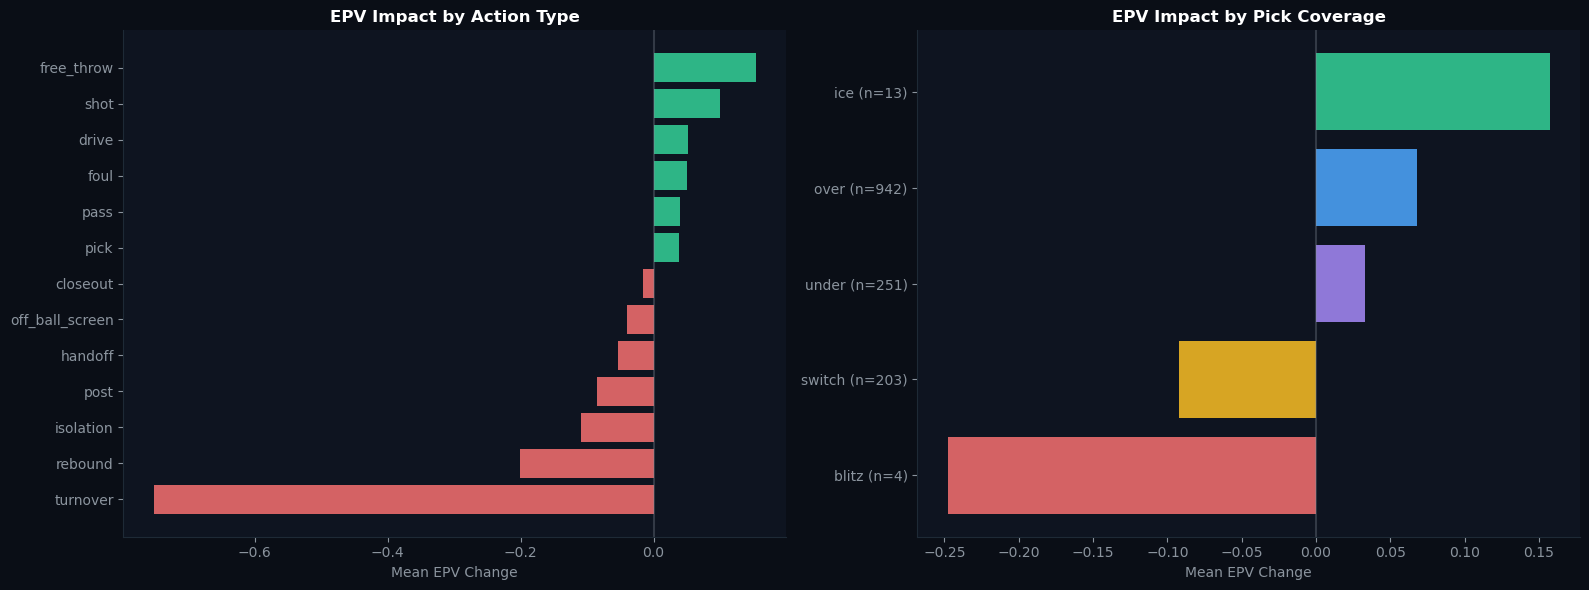

In [6]:
fig,axes=plt.subplots(1,2,figsize=(16,6),facecolor='#0a0e16')
ax=axes[0];ax.set_facecolor('#0e1420')
colors=['#34d399' if v>0 else '#f87171' for v in adf['mean_delta']]
ax.barh(range(len(adf)),adf['mean_delta'],color=colors,alpha=0.85)
ax.set_yticks(range(len(adf)));ax.set_yticklabels(adf['action'],color='#8b949e')
ax.invert_yaxis();ax.set_xlabel('Mean EPV Change',color='#8b949e')
ax.set_title('EPV Impact by Action Type',color='white',fontweight='bold')
ax.axvline(x=0,color='#8b949e',alpha=0.3)
ax.tick_params(colors='#8b949e');ax.spines['bottom'].set_color('#1e2a36');ax.spines['left'].set_color('#1e2a36')
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)

ax=axes[1];ax.set_facecolor('#0e1420')
cc={'over':'#4ea8ff','under':'#a78bfa','switch':'#fbbf24','ice':'#34d399','blitz':'#f87171'}
cdata=[(c,np.mean(d),len(d)) for c,d in cd.items() if len(d)>=3]
cdata.sort(key=lambda x:x[1],reverse=True)
if cdata:
    cn,cm,ccn=zip(*cdata)
    ax.barh(range(len(cn)),cm,color=[cc.get(c,'#888') for c in cn],alpha=0.85)
    ax.set_yticks(range(len(cn)));ax.set_yticklabels([f"{c} (n={n})" for c,n in zip(cn,ccn)],color='#8b949e')
    ax.invert_yaxis();ax.axvline(x=0,color='#8b949e',alpha=0.3)
ax.set_xlabel('Mean EPV Change',color='#8b949e')
ax.set_title('EPV Impact by Pick Coverage',color='white',fontweight='bold')
ax.tick_params(colors='#8b949e');ax.spines['bottom'].set_color('#1e2a36');ax.spines['left'].set_color('#1e2a36')
ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('epv_v2_action_analysis.png',dpi=150,facecolor='#0a0e16',bbox_inches='tight')
plt.show()
